# 02. Data Analysis & Visualization
descrizione

### Indice Capitoli
- **Prefazione: Data Loading** Caricamento dei 13 dataset e verifica dtypes.
- **Capitolo 1: Analisi Temporale**
- **Capitolo 2: Analisi Geografica**

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
%load_ext autoreload
%autoreload 2
from functions.utils import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


##  Prefazione: Data Loading

In questa sezione vengono caricati i dataset già puliti
e preparati nel notebook precedente. L’obiettivo è rendere i dati
pronti per l’analisi e garantire che i tipi di dato (dtypes) siano
corretti e coerenti.  
Alcune operazioni di conversione dei tipi di dato erano già state effettuate
nel notebook precedente; tuttavia, poiché Pandas non mantiene i tipi al
riaprirsi del file, le conversioni dovranno essere eseguite nuovamente.

In [2]:
characters_df = pd.read_csv("../data/processed/Characters_cleaned.csv")
character_anime_works_df = pd.read_csv("../data/processed/Character_anime_works_cleaned.csv")
character_nicknames_df = pd.read_csv("../data/processed/Character_nicknames_cleaned.csv")
details_df = pd.read_csv("../data/processed/Details_cleaned.csv")
favs_df = pd.read_csv("../data/processed/Favs_cleaned.csv")
person_alternate_names_df = pd.read_csv("../data/processed/Person_alternate_names_cleaned.csv")
person_anime_works_df = pd.read_csv("../data/processed/Person_anime_works_cleaned.csv")
person_voice_works_df = pd.read_csv("../data/processed/Person_voice_works_cleaned.csv")
person_details_df = pd.read_csv("../data/processed/Person_details_cleaned.csv")
profiles_df = pd.read_csv("../data/processed/Profiles_cleaned.csv")
ratings_df = pd.read_csv("../data/processed/Ratings_cleaned.csv")
recommendations_df = pd.read_csv("../data/processed/Recommendations_cleaned.csv")
stats_df = pd.read_csv("../data/processed/Stats_cleaned.csv")

Le colonne contenenti date vengono convertite in
tipo `datetime` per consentire operazioni temporali corrette.

In [4]:
# Dataset Person_details
person_details_df = convert_to_datetime(person_details_df, "birthday")

# Dataset Profiles
profiles_df = convert_to_datetime(profiles_df, "joined")
profiles_df = convert_to_datetime(profiles_df, "birthday")

# Dataset Details
details_df = convert_to_datetime(details_df, "start_date")
details_df = convert_to_datetime(details_df, "end_date")

Column 'birthday' successfully converted.
Column 'joined' successfully converted.
Column 'birthday' successfully converted.
Column 'start_date' successfully converted.
Column 'end_date' successfully converted.


Le colonne numeriche che contengono solo valori interi ma includono
  valori NaN vengono convertite in `Int64` (tipo intero
  compatibile con NaN), evitando così che siano trattate come float64.

In [6]:
# Dataset Details
details_df["year"] = details_df["year"].astype("Int64")
details_df["scored_by"] = details_df["scored_by"].astype("Int64")
details_df["rank"] = details_df["rank"].astype("Int64")
details_df["episodes"] = details_df["episodes"].astype("Int64")

# Dataset Characters
characters_df["favorites"] = characters_df["favorites"].astype("Int64")
characters_df["character_mal_id"] = characters_df["character_mal_id"].astype(int)

# Dataset Profiles
profiles_df["watching"] = profiles_df["watching"].astype("Int64")
profiles_df["completed"] = profiles_df["completed"].astype("Int64")
profiles_df["on_hold"] = profiles_df["on_hold"].astype("Int64")
profiles_df["dropped"] = profiles_df["dropped"].astype("Int64")
profiles_df["plan_to_watch"] = profiles_df["plan_to_watch"].astype("Int64")

## Capitolo 1: Analisi Temporale

L’animazione giapponese ha conosciuto una crescita significativa nel corso del XX e XXI secolo.    
Per questa analisi sono stati considerati solo gli anime narrativi principali, escludendo titoli di tipo *Music*, *CM* (Commercials) e *PV* (Promotional Videos).  
I dati relativi al 2026 non sono stati presi in considerazione poiché parziali e non significativi.  
Per gli anime privi di anno è stato utilizzato l’anno di `start_date`.  

### Evoluzione della produzione annuale di anime


Il grafico mostra l'evoluzione del numero di anime prodotti ogni anno.   

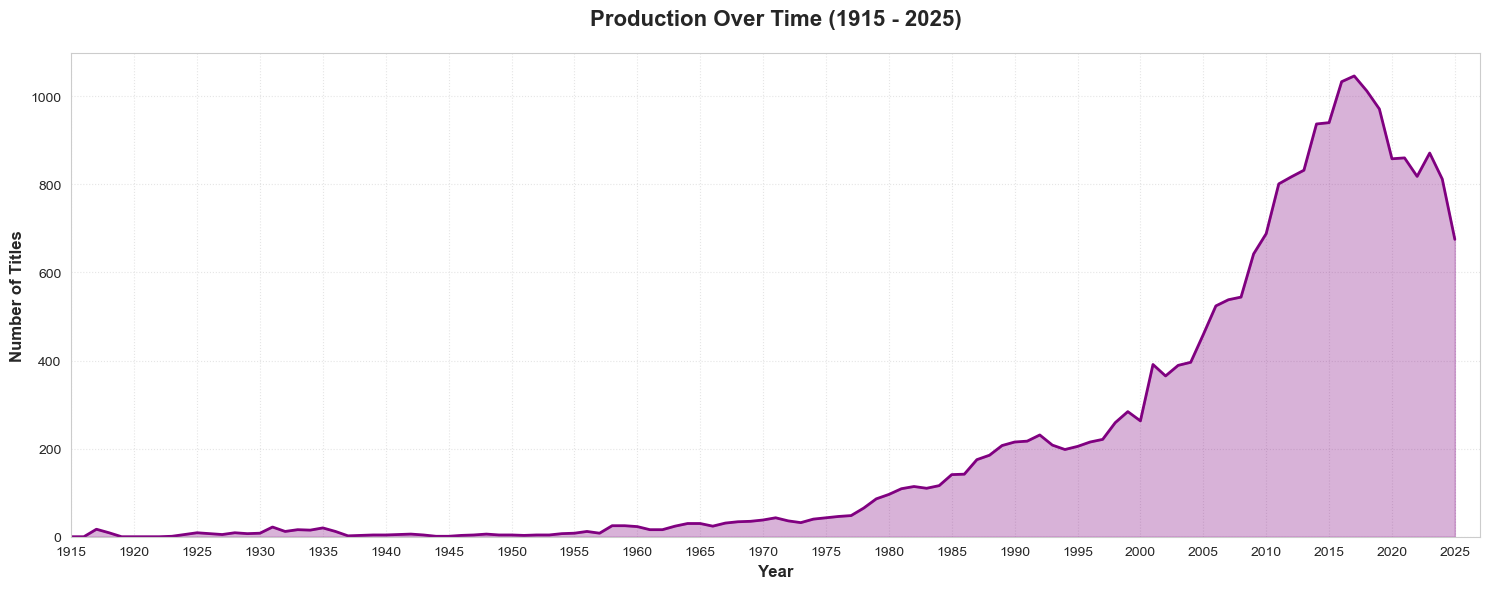

In [8]:
plot_yearly_production(details_df)

- **Dal 1915 al 1955 – Le origini**  
In questo periodo la produzione di anime era quasi nulla, con 0, massimo 2 titoli all’anno. Gli anime erano cortometraggi sperimentali  
destinati principalmente ai cinema. La televisione non era ancora diffusa, quindi non esistevano serie TV come quelle che conosciamo oggi.

- **Dal 1956 al 1975 – I primi passi**  
L’avvento della televisione favorisce la nascita dei primi anime per il piccolo schermo. La produzione annua cresce e nascono opere  
iconiche come *Lupin III*, *Rocky Joe* e *Heidi* che che contribuiscono ad attirare sempre più l’interesse del pubblico e a stimolare la produzione di anime televisivi.

- **Dal 1976 al 2000 – La crescita**  
La produzione accelera sensibilmente, questo periodo vede la nascita di grandi franchise come *Dragon Ball*, *One Piece*, *Neon Genesis   
Evangelion* e *Cowboy Bebop*. Gli anime diventano un fenomeno culturale globale e la produzione annuale aumenta rapidamente.

- **Dal 2001 al 2017 – Il boom**  
Il numero di titoli prodotti ogni anno cresce esponenzialmente, raggiungendo il suo picco massimo intorno al 2017. Alcuni titoli rappresentativi   
di questo periodo sono *Attack on Titan*, *One Punch Man* e *My Hero Academia*. La nascita delle piattaforme streaming come Netflix e CrunchyRoll accelerano ulteriormente la produzione e la diffusione degli anime.

- **Dal 2018 ad oggi – Il mercato moderno**  
Negli anni più recenti la produzione segna un calo rispetto agli anni precedenti. Questo riflette un mercato ormai saturo e competitivo,  
dove gli studios selezionano con un po' più attenzione i progetti per evitare rischi finanziari.

**Analisi Complessiva**  
L’evoluzione della produzione anime mostra tre fasi principali: una fase iniziale lenta, una crescita rapida e un periodo di moderata discesa recente. La crescita è stata favorita dalla televisione, dall’espansione internazionale e dalle innovazioni tecnologiche nell’animazione digitale. Negli ultimi anni la discesa della produzione indica un mercato competitivo dove gli studios prestano maggiore attenzione alla qualità rispetto alla quantità.


### Distribuzione della produzione annuale per fonte

Il grafico mostra la suddivisione degli anime prodotti in base alla loro fonte originale.  
La categoria `Unknown` è stata esclusa, in quanto non rilevante ai fini dell’analisi.  

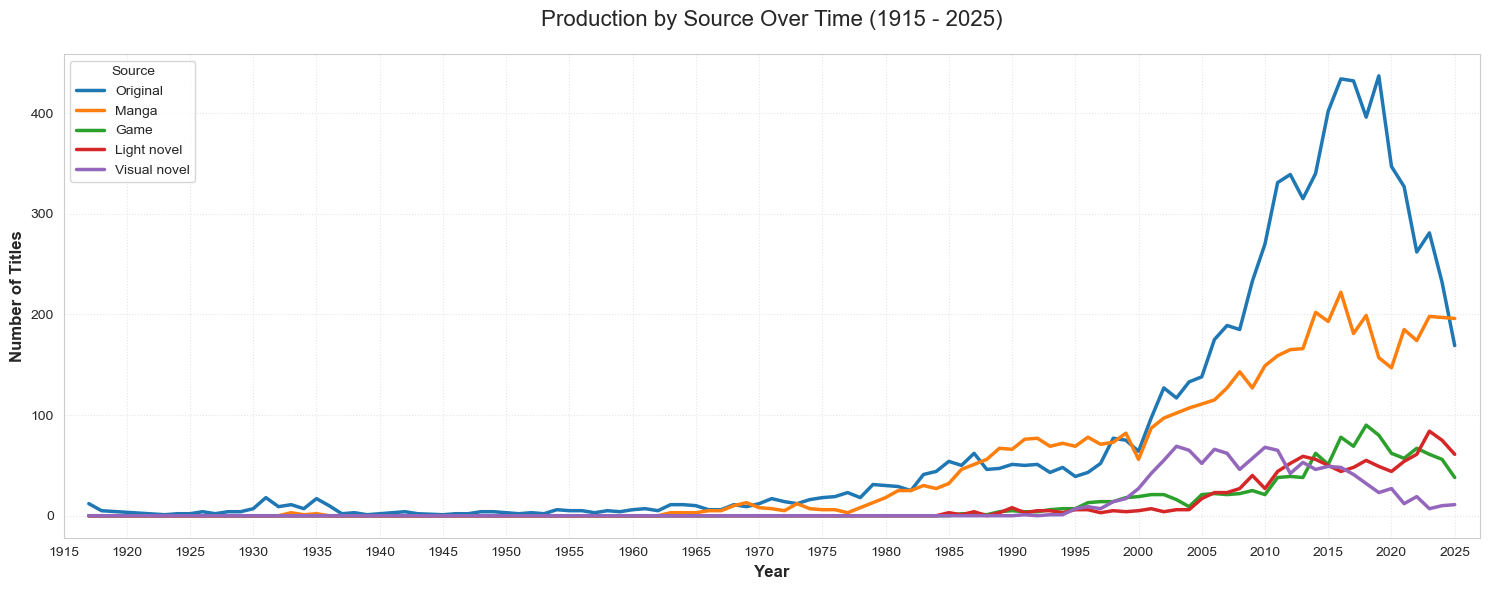

In [9]:
plot_production_by_source(details_df)

- **I primi anni**  
Nei primi lavori di animazione, la maggior parte degli anime erano *original*, mentre gli adattamenti da *manga* erano pochi. Fino al 1965  
circa, gli anime original dominavano perché erano più semplici da produrre e permettevano agli studi di sperimentare nuovi stili e format  
televisivi. Gli adattamenti da *manga* erano limitati perché i *manga* pubblicati e popolari era ancora ristretta.

- **La crescita degli adattamenti Manga**  
Dal 1965 in poi si inizia a produrre più anime tratti da manga rispetto al passato. Gli *original* continuano a essere numerosi,  
ma a partire dalla seconda metà degli anni ’80 i *manga* li superano grazie alla loro capacità di attrarre una fanbase già consolidata,  
ciò riduce i rischi per gli studios. 
 
- **La rapida ascesa degli Original**  
Dopo il 2000, si osserva una grande crescita degli anime *original*, favorita dalla nascita di piattaforme streaming e e digitali.   
Questi canali permettono agli studios di raggiungere un pubblico globale senza dipendere dai franchise già esistenti. Gli *original*   
offrono più libertà creativa e l’opportunità di lanciare nuovi franchise, motivo per cui la loro produzione cresce rapidamente rispetto al passato.

- **Trend degli Original e Manga**   
Gli anime *original* mostrano una crescita più rapida, ma anche un calo altrettanto veloce negli ultimi anni, mentre gli adattamenti da   
*manga* seguono una linea in crescita più stabile. 

- **Altre fonti popolari: Giochi, Light Novel e Visual Novel**  
A partire dagli anni 2000, cresce la produzione di anime tratti da *giochi*, *light novel* e *visual novel*. Le *visual novel* hanno visto   
un calo costante negli ultimi anni; al contrario le *light novel* registrano una crescita costante grazie a serie di successo come *Sword Art Online* e *Re:Zero*.

**Analisi Complessiva**  
La distribuzione annuale della produzione anime per fonte evidenzia la predominanza degli *original* e degli adattamenti da *manga*. Gli *original*   
superano numericamente di gran lunga le altre categorie, ma la maggior parte dei grandi successi proviene principalmente dai *manga*,  
come *Attack on Titan*, *Death Note* e *Naruto*. 

### Popolarità media degli anime negli anni

- Il grafico mostra la popolarità media degli anime per anno di uscita, a partire dal 1960.  
- Gli anni precedenti sono stati esclusi perché i dati erano pochi e spesso nulli.  

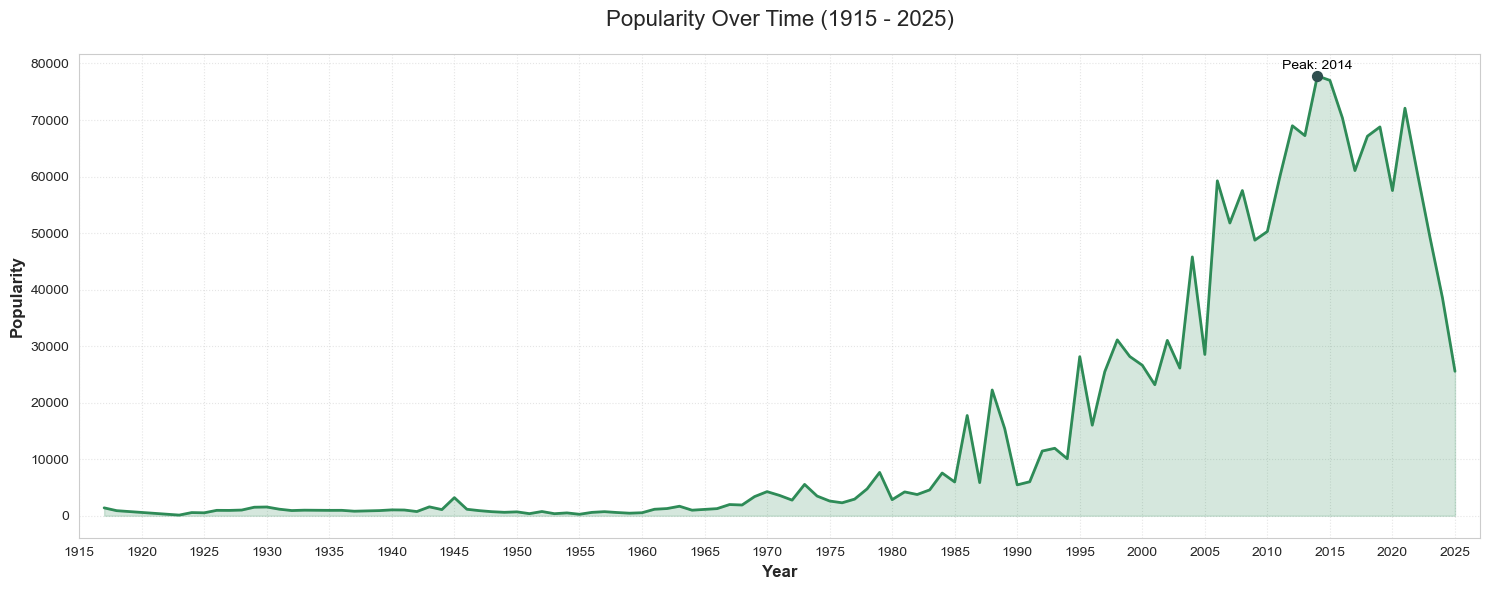

In [42]:
plot_popularity(details_df)

Possiamo osservare come la popolarità media dei titoli sia cresciuta nel tempo. Questo aumento è legato all’incremento della produzione: con più titoli disponibili, è più probabile che emergano serie di grande successo che alzano la popolarità complessiva.  
**Nella seconda metà degli anni ’80** si notano alcuni picchi improvvisi, dovuti all’uscita di anime iconici che fanno salire la media, anche se molti titoli restavano poco conosciuti.  
**Dal 2000 in poi**, la popolarità media cresce più rapidamente, raggiungendo il suo picco nel 2014 grazie a serie come *Tokyo Ghoul*, *Noragami* e *No Game No Life*, che hanno attirato milioni di fan.  
**Negli anni più recenti** si osserva una leggera diminuzione della popolarità media, parallela al calo della produzione. Tuttavia, molti nuovi titoli hanno ancora bisogno di tempo per consolidare la propria fanbase o non sono ancora conclusi, quindi questo calo non va interpretato come definitivo.

---
Proviamo a visualizzare la popolarità media escludendo i titoli troppo di nicchia; prendiamo solo anime con `members` > 5.000.

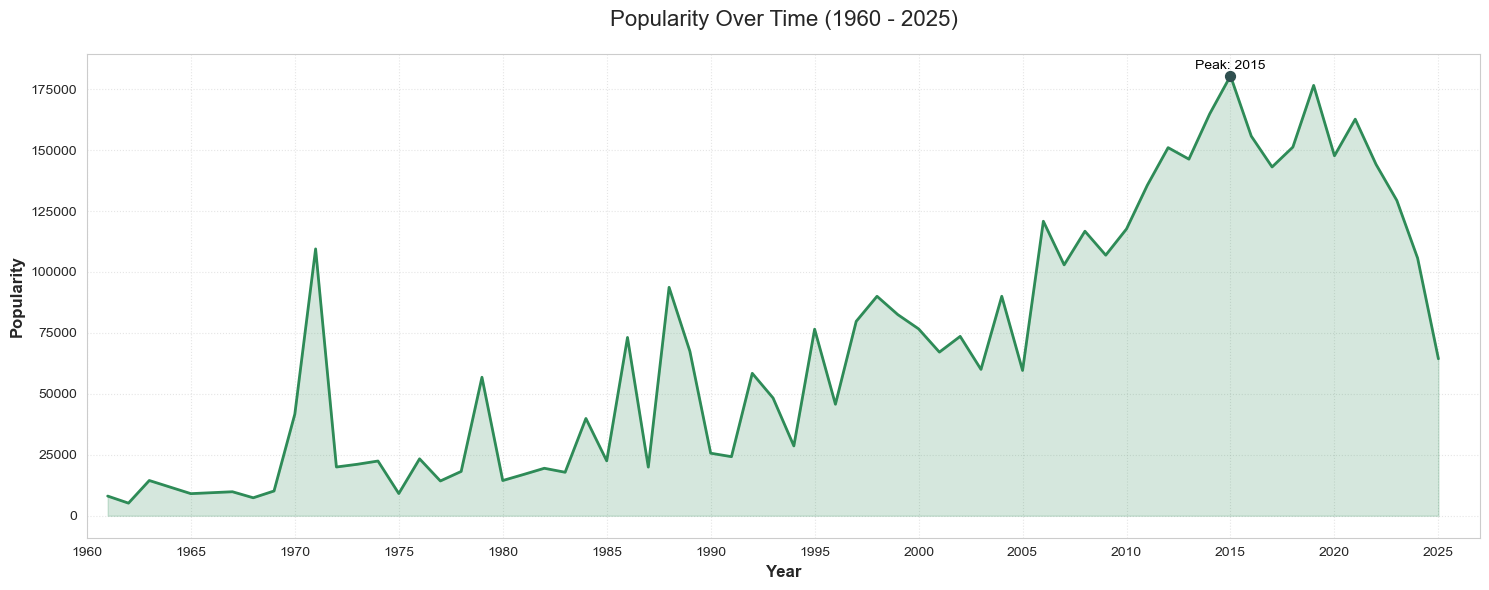

In [33]:
plot_popularity_filtred(details_df)

La popolarità media filtrata non mostra una crescita costante come prima.   
**XX secolo** si osservano picchi più importanti e oscillazioni rispetto al grafico precedente. In questo periodo i titoli famosi erano pochi, quindi la media è  
stata influenzata fortemente dai pochi anime che hanno ottenuto grande successo, mentre i meno famosi, nonchè la maggior parte, sono stati  scartati.  
**Negli anni più recenti** invece ci sono molti più titoli che superano la soglia minima per essere inclusi nella media, rendendo  
l’andamento più stabile e distribuito, simile a quello della popolarità sul totale.

---

**Analisi Complessiva**   
La popolarità filtrata evidenzia i grandi successi e i picchi legati agli anime più famosi, mentre la totale mostra un andamento più regolare.
Negli anni '70-’80-'90 i pochi titoli popolari alzano la media filtrata, mentre negli anni più recenti molti titoli superano la soglia minima, rendendo il trend più stabile. 

### Valutazione media degli anime negli anni

- Il primo grafico mostra la valutazione media degli anime per anno di uscita, a partire dal 1915.  
- Nel secondo invece abbiamo la versione filtrata per `scored_by` > 4.000. Gli anni precedenti al 1960 sono stati esclusi perché i dati erano nulli. 

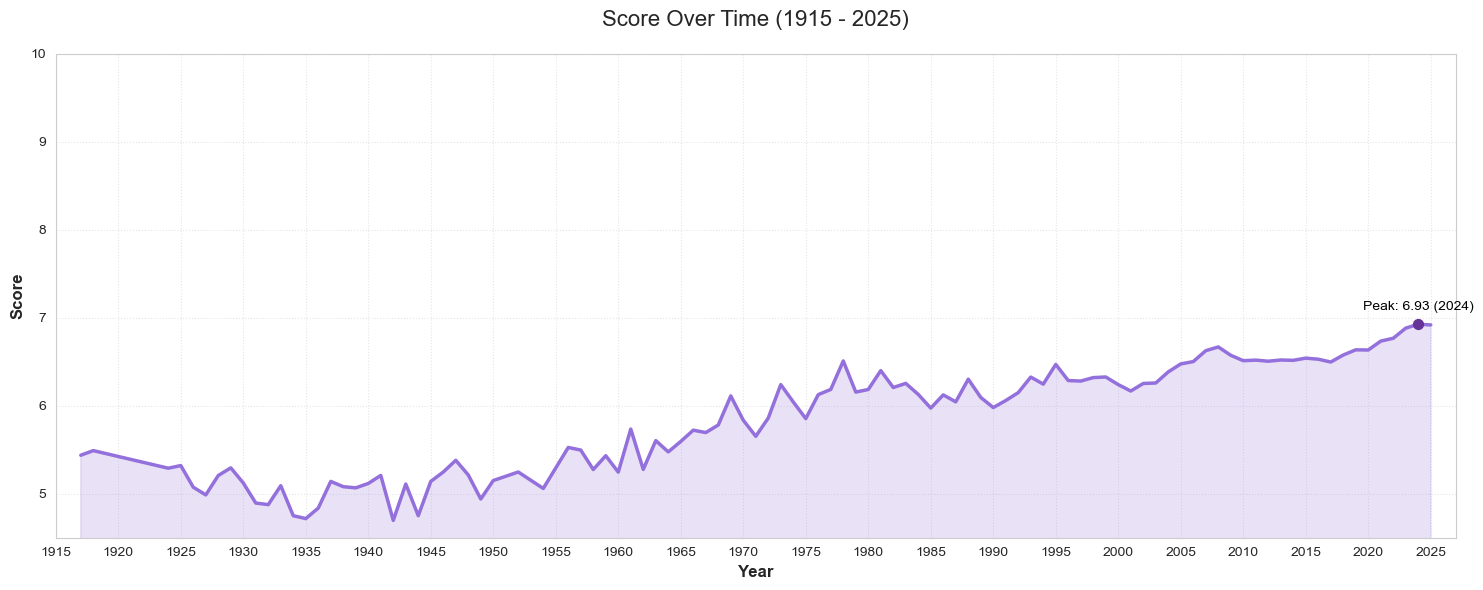

In [41]:
plot_score(details_df)

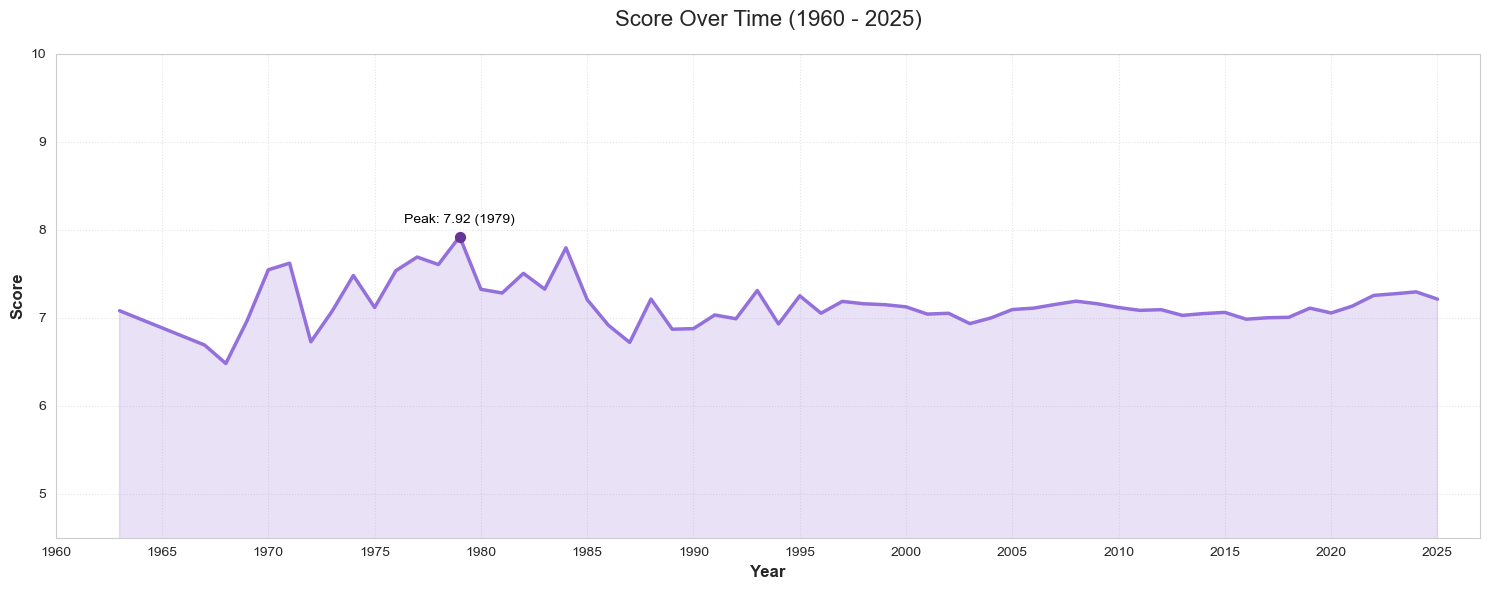

In [36]:
plot_score_filtred(details_df)

Possiamo osservare come cambia la distribuzione nei due grafici:
- **Nel primo grafico** la valutazione media per anno rimane abbastanza stabile, con una moderata crescita nel tempo. Questo differisce un po' dalla popolarità totale, che ha mostrato un aumento più rapido.
- **Nel secondo grafico** la valutazione media dei titoli più conosciuti mostra più picchi negli anni passati, mentre oggi risultano più stabile. I picchi del passato erano causati da pochi titoli, ma generalmente con valutazioni molto alte.

**Analisi Complessiva**  
La valutazione media totale mostra un andamento stabile nel tempo, con una lieve crescita che riflette un miglioramento complessivo della  
qualità delle produzioni moderne.  
La valutazione media dei titoli più conosciuti, invece, presenta più oscillazioni e picchi negli anni passati. Questo è dato dai pochi  
anime prodotti in quegli anni.  
Negli anni recenti, con un numero maggiore di titoli popolari, sia la valutazione totale sia quella filtrata risultano stabili.  
Da quanto visto possiamo dire che mediamente gli anime più conosciuti tendono ad avere valutazioni più alte, mentre gli anime più  
sconosciuti abbassano la media totale. 

### Evoluzione annuale del numero medio di episodi

- Il grafico mostra l’andamento della produzione anime annuale a partire dal 1960.  
- Sono inclusi esclusivamente gli anime di tipo `TV` e `ONA`, in quanto l’analisi si concentra sull’evoluzione delle serie.   
- Sono stati presi in considerazione solo i titoli con stato `Finished Airing`, per garantire una maggiore accuratezza dei dati.  
- Gli anni precedenti al 1960 non sono rappresentati poiché privi di dati significativi.  
- Per gli anni con un numero ridotto di titoli, è stato indicato il conteggio degli anime prodotti, così da evidenziare che i valori medi  
sono calcolati su un campione limitato.

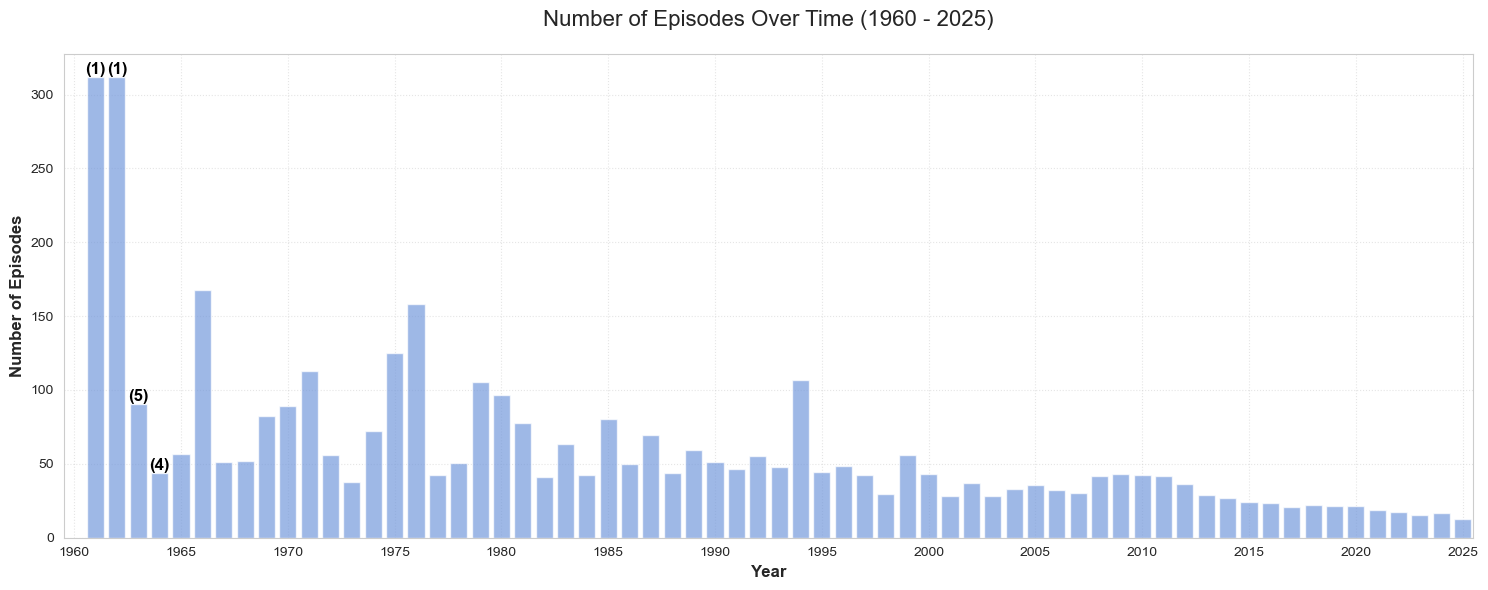

In [109]:
plot_episodes(details_df)

- **Fase Iniziale: oscillazioni e serie lunghe**  
Dal 1960 fino alla prima metà degli anni ’90, il numero medio di episodi per anime mostra forti oscillazioni.  
Questo andamento irregolare è in parte legato al numero ridotto di serie prodotte nei primi decenni, che rende la media molto sensibile  
alla presenza di poche serie particolarmente lunghe. In questo periodo erano infatti comuni anime con un alto numero di episodi, pensati  
per una programmazione televisiva continuativa.

- **Stabilizzazione**  
A partire dalla seconda metà dagli anni ’90 il numero medio di episodi inizia a diminuire in modo più stabile, con oscillazioni meno    
marcate. Le serie diventano più brevi e organizzate in stagioni.

- **Audience Moderna**  
Dal 2010 in poi, la discesa del numero medio di episodi diventa ancora più evidente. Questo è dovuto anche al fatto che le serie divise  
in stagioni brevi sono più facili da seguire e completare, adattandosi meglio alle abitudini del pubblico.

**Analisi Complessiva**    
Comparando questa analisi con quella della produzione annuale, si evidenzia chiaramente il passaggio da poche serie lunghe negli anni    
iniziali a produzioni più brevi, ma più numerose e diversificate. Le serie lunghe richiedono un impegno maggiore per essere seguite e   
completate, mentre il pubblico moderno tende a preferire stagioni brevi e autoconclusive.



## Capitolo 2: Analisi Correlativa tra Generi e Demografiche

### Distribuzione dei generi anime

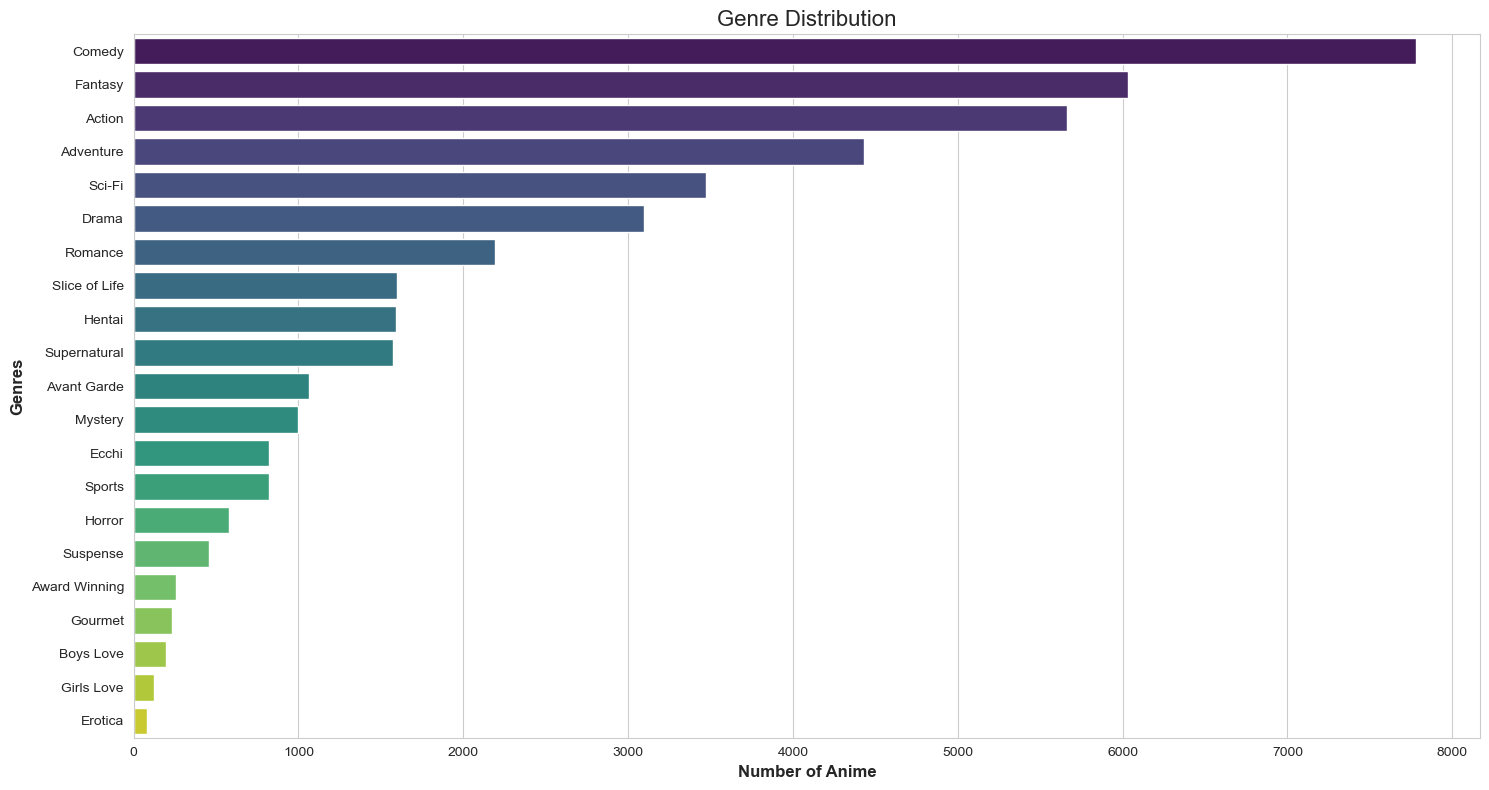

In [145]:
plot_genres(details_df)

### Distribuzione delle demografiche

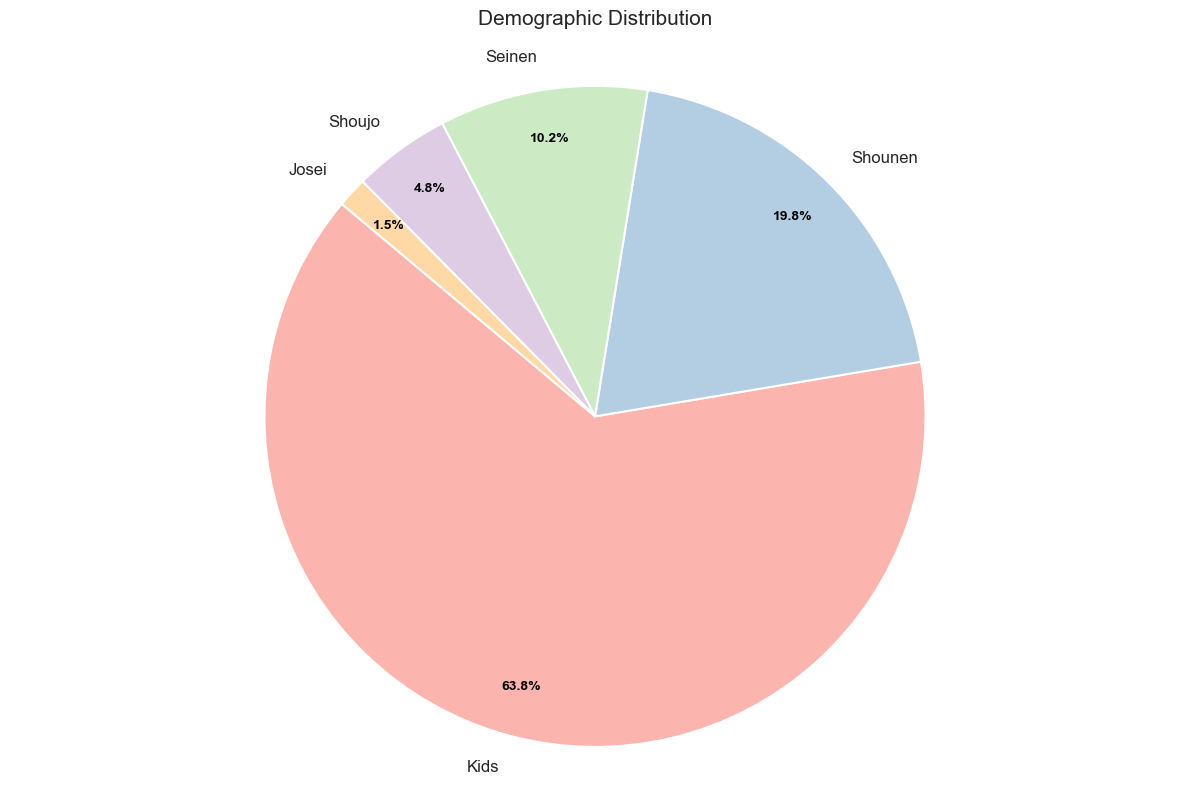

In [147]:
plot_demographics(details_df)

### Generi dominanti per target

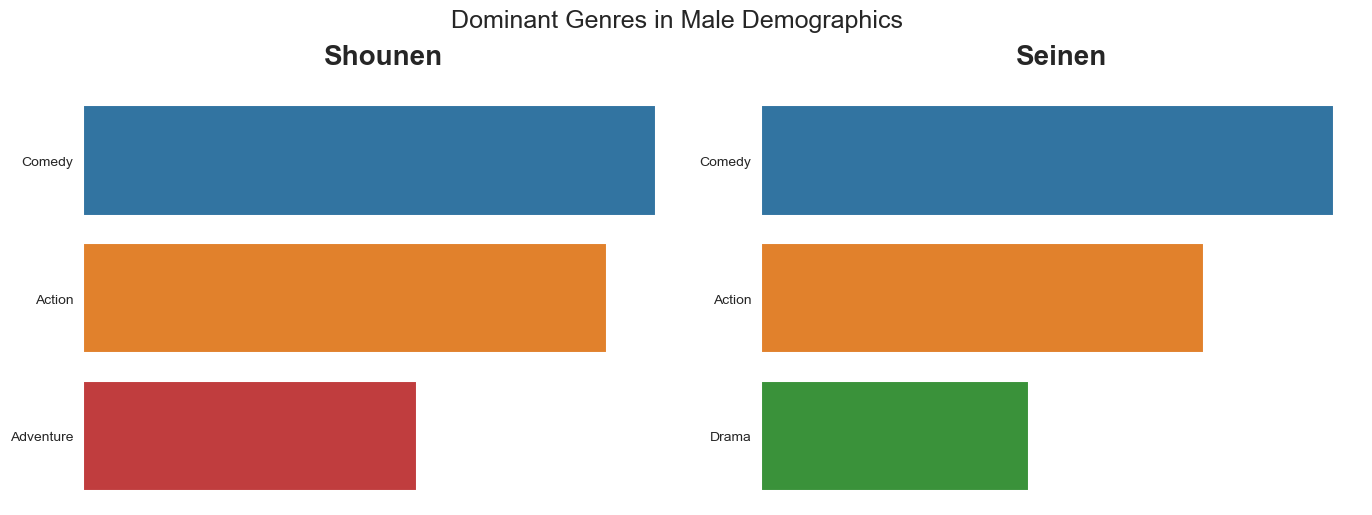

In [130]:
plot_male_demographics(details_df)

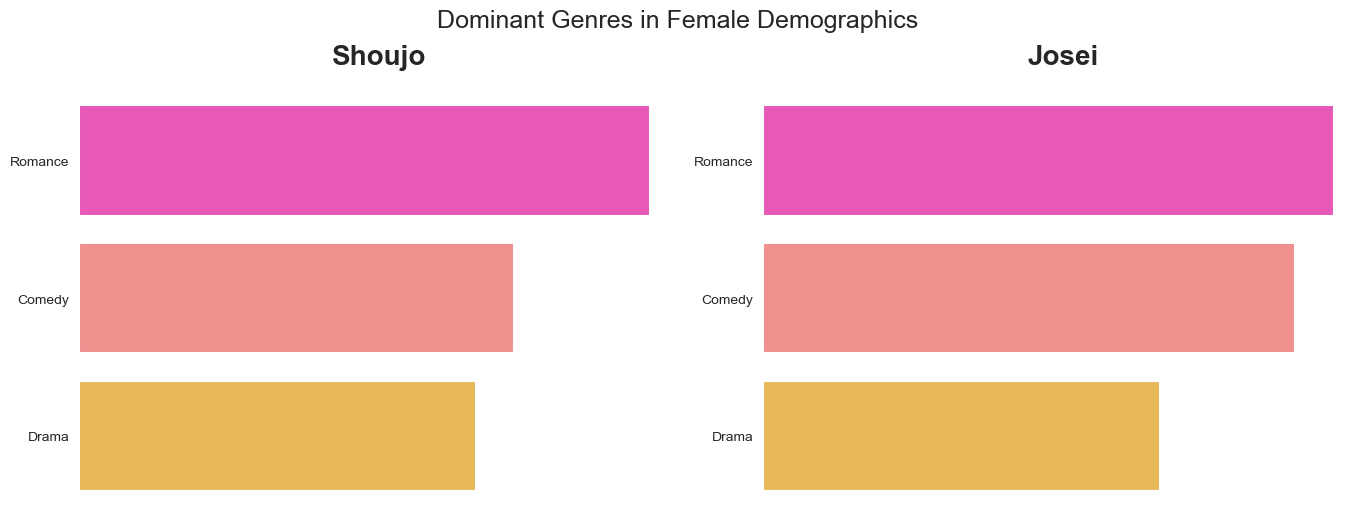

In [129]:
plot_female_demographics(details_df)

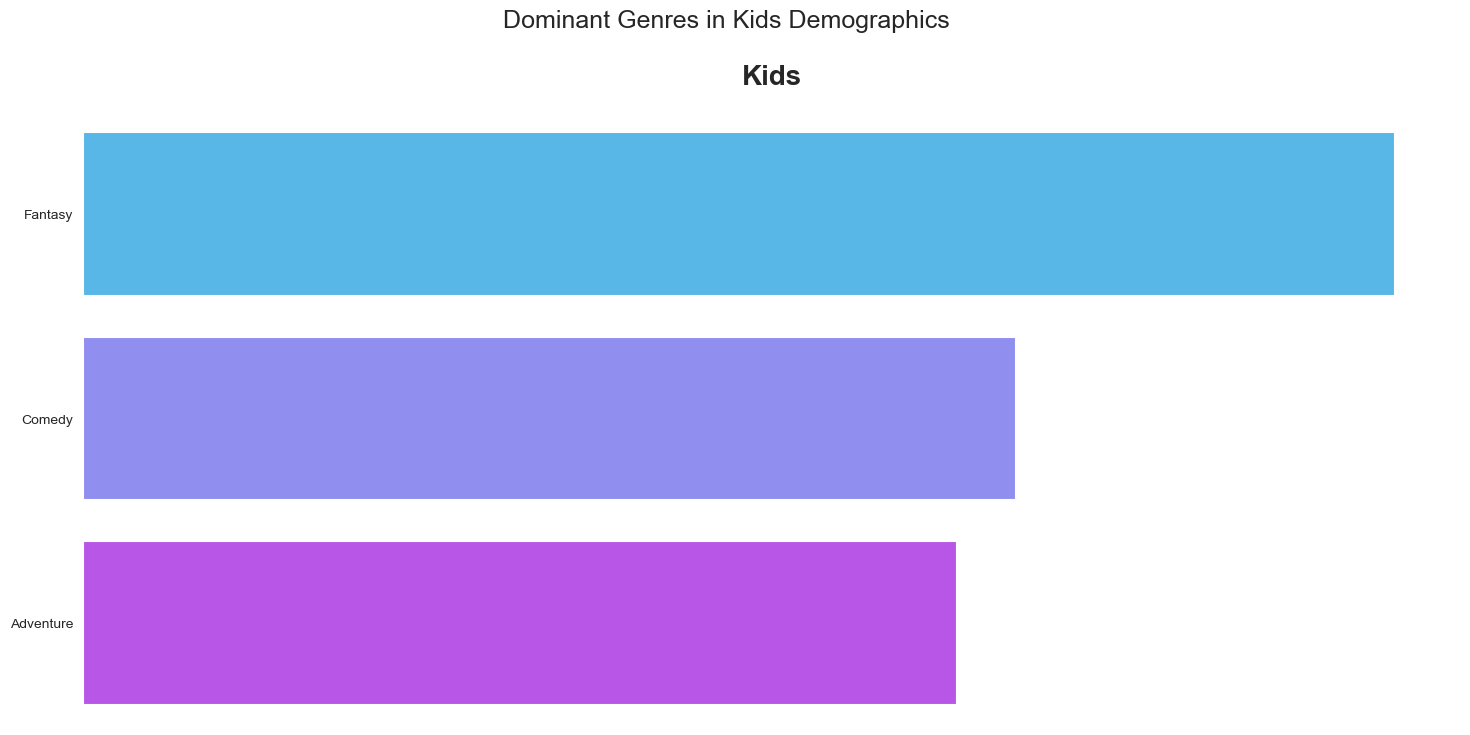

In [128]:
plot_kids_demographics(details_df)

### Valutazione media per genere

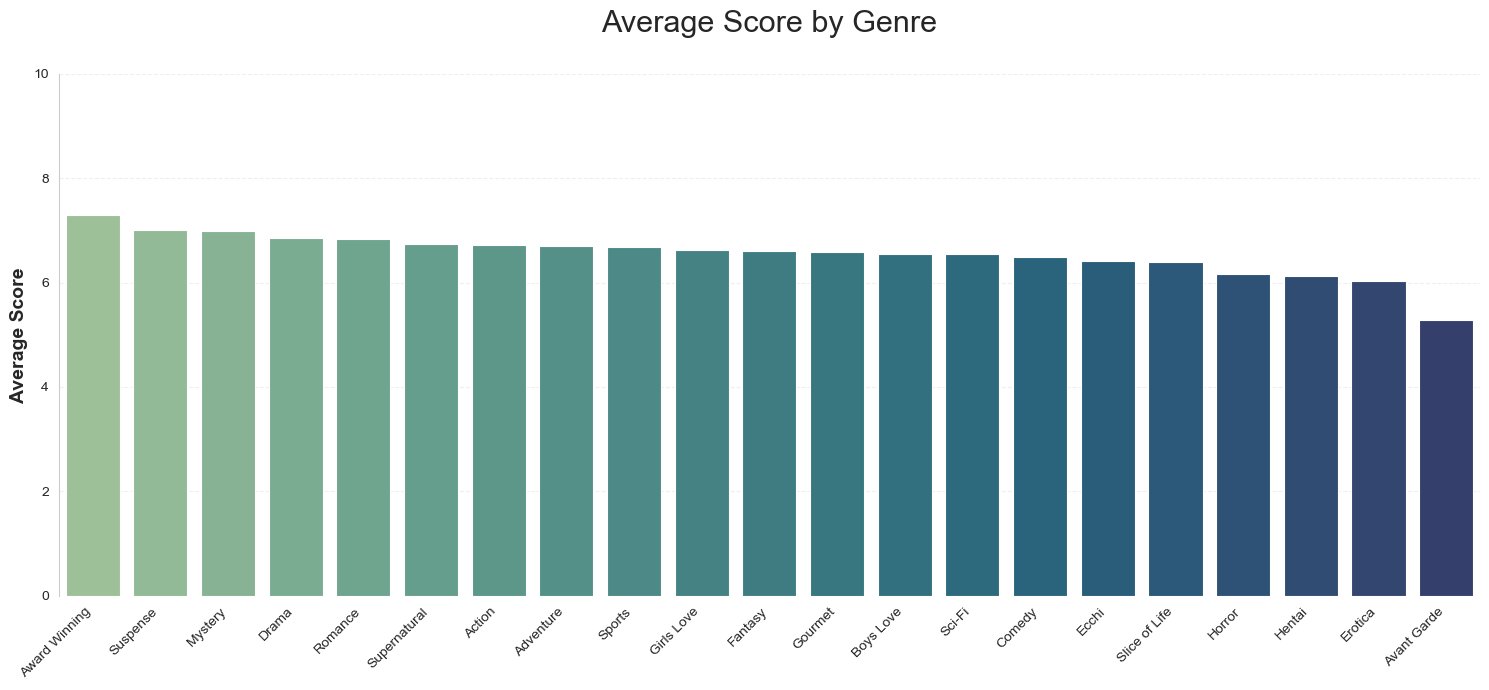

In [142]:
plot_genres_score(details_df)